# Lecture 20

Today's Topics:

- Attention as a Soft Dictionary Lookup
- Self-Attention from Scratch
    - Why Divide by $\sqrt{d}$?
    - Positions: Why "Dog Bites Man" Needs Them
- Causal Masking: No Peeking at the Future
- Multi-Head Attention
- Building and Training a Tiny GPT
- Sampling: Temperature and Top-k
- Inside GPT-2
- Back to Stable Diffusion: Cross-Attention

In [15]:
import math
import time
import numpy as np
import matplotlib.pyplot as plt

import torch
from torch import nn
import torch.nn.functional as F

print(f"PyTorch version: {torch.__version__}")
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device: {device}")

PyTorch version: 2.15.0+cu132
Device: cpu


## Attention as a Soft Dictionary

A Python dictionary does an **exact** lookup: you give it a key, it returns that key's value, and anything else is a `KeyError`.

**Attention** is a *soft* lookup. Every entry has a **key** vector and a **value**. You give it a **query** vector, and instead of finding one exact match, it:

1. scores the query against every key with a dot product (similar directions → high score),
2. turns the scores into weights that add up to 1 with **softmax**,
3. returns the **weighted average** of the values.

A query that's halfway between two keys gets a blend of their values. It's a dictionary that never throws `KeyError`.

Here's an example. Each word's key is a made-up 2D vector (animals point one way, vehicles another), and its value is how many wheels it has.

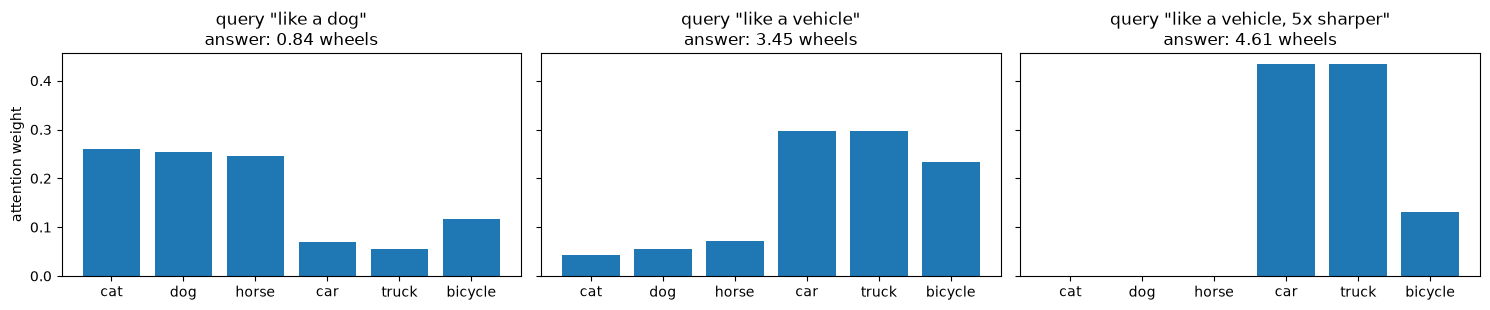

In [16]:
words  = ["cat", "dog", "horse", "car", "truck", "bicycle"]
keys   = torch.tensor([[1.0, 0.1], [0.9, 0.3], [0.8, 0.5], [-0.7, 0.8], [-0.9, 0.6], [-0.2, 1.0]])
wheels = torch.tensor([0.0, 0.0, 0.0, 4.0, 6.0, 2.0])   # the values


def soft_lookup(query, keys, values):
    scores = keys @ query                  # 1. similarity of the query to every key
    weights = torch.softmax(scores, dim=0) # 2. turn scores into weights that sum to 1
    return weights @ values, weights       # 3. weighted average of the values


queries = {"like a dog": torch.tensor([0.9, 0.3]),
           "like a vehicle": torch.tensor([-0.8, 0.8]),
           "like a vehicle, 5x sharper": 5 * torch.tensor([-0.8, 0.8])}

fig, axes = plt.subplots(1, 3, figsize=(15, 3.2), sharey=True)
for ax, (name, q) in zip(axes, queries.items()):
    out, w = soft_lookup(q, keys, wheels)
    ax.bar(words, w)
    ax.set_title(f'query "{name}"\nanswer: {out:.2f} wheels')
axes[0].set_ylabel("attention weight")
plt.tight_layout()
plt.show()

- A query **like a dog** spreads its weight over the three animals, so the answer is a weighted average of their wheels: 0.84, mostly 0 with a little leaking in from the vehicles.
- A query **like a vehicle** puts most weight on car, truck and bicycle, so the answer is a blend of 4, 6 and 2 wheels (3.45).
- **Multiplying the query by 5** makes every score 5 times bigger, and softmax turns bigger gaps into sharper weights: the animals drop to zero, and the answer moves to 4.61, mostly car and truck. Scaling the scores controls how "soft" the lookup is. We'll meet this twice more today: dividing by $\sqrt{d}$, and temperature.

In a Transformer, nobody hand-picks the keys and values. They're produced by learned linear layers, and training decides what each token should look for and what it should offer.

## Self-Attention from Scratch

In **self**-attention, the dictionary *is* the sentence. Every token plays all three roles at once:

- a **query**: "what am I looking for?"
- a **key**: "what do I contain?"
- a **value**: "what will I pass on if someone attends to me?"

Each role gets its own learned linear layer ($W_Q$, $W_K$, $W_V$) applied to the token's embedding. Then every token looks up every token, including itself. With all the queries stacked into a matrix $Q$ (one row per token), and likewise $K$ and $V$, the whole thing is one line:

$$\text{Attention}(Q, K, V) = \text{softmax}\left(\frac{QK^\top}{\sqrt{d}}\right) V$$

Row $i$ of $QK^\top$ holds token $i$'s scores against every token. Softmax turns each row into weights, and multiplying by $V$ takes the weighted averages. 

In [17]:
def attention(Q, K, V, mask=None):
    # Q: [..., n_queries, d]   K, V: [..., n_keys, d]
    d = Q.shape[-1]
    scores = Q @ K.transpose(-2, -1) / math.sqrt(d)             # [..., n_queries, n_keys]
    if mask is not None:
        scores = scores.masked_fill(mask == 0, float("-inf"))   # blocked positions get weight 0
    weights = torch.softmax(scores, dim=-1)                     # each row sums to 1
    return weights @ V, weights


torch.manual_seed(0)
n_tokens, d_model, d_head = 5, 16, 8
X = torch.randn(n_tokens, d_model)                # 5 token embeddings, 16 numbers each
W_Q = nn.Linear(d_model, d_head, bias=False)
W_K = nn.Linear(d_model, d_head, bias=False)
W_V = nn.Linear(d_model, d_head, bias=False)

out, weights = attention(W_Q(X), W_K(X), W_V(X))
print(f"input  X:        {tuple(X.shape)}")
print(f"weights:         {tuple(weights.shape)}  (each token's weights over all 5 tokens)")
print(f"output:          {tuple(out.shape)}")
print(f"rows sum to 1:   {weights.sum(dim=-1)}")

# PyTorch has this built in; ours should match it
builtin = F.scaled_dot_product_attention(W_Q(X), W_K(X), W_V(X))
print(f"matches F.scaled_dot_product_attention: {torch.allclose(out, builtin, atol=1e-6)}")

input  X:        (5, 16)
weights:         (5, 5)  (each token's weights over all 5 tokens)
output:          (5, 8)
rows sum to 1:   tensor([1.0000, 1.0000, 1.0000, 1.0000, 1.0000], grad_fn=<SumBackward1>)
matches F.scaled_dot_product_attention: True


That's the entire mechanism. Everything else in a Transformer is built around this function.

The output for each token is a mix of the values of the tokens it attended to. So after attention, the vector for "it" in "the animal didn't cross the street because it was too tired" can carry information *from* "animal". The word's meaning now depends on its context, which is what makes Transformer embeddings so useful.

## Why Divide by $\sqrt{d}$?

The paper's reason (section 3.2.1): when $d$ is large, dot products get large, which pushes softmax into regions where it has "extremely small gradients".

Let's check. A dot product of two random vectors with $d$ entries adds up $d$ random products, so its typical size grows like $\sqrt{d}$. We'll score one query against 10 random keys, for several values of $d$, and measure how much weight goes to the single top key:

d =    4 | std of scores:    2.0 | top weight, no scaling: 0.49 | top weight, divided by sqrt(d): 0.31
d =   16 | std of scores:    4.0 | top weight, no scaling: 0.72 | top weight, divided by sqrt(d): 0.32
d =   64 | std of scores:    8.0 | top weight, no scaling: 0.86 | top weight, divided by sqrt(d): 0.32
d =  256 | std of scores:   16.1 | top weight, no scaling: 0.93 | top weight, divided by sqrt(d): 0.32
d = 1024 | std of scores:   32.2 | top weight, no scaling: 0.96 | top weight, divided by sqrt(d): 0.32


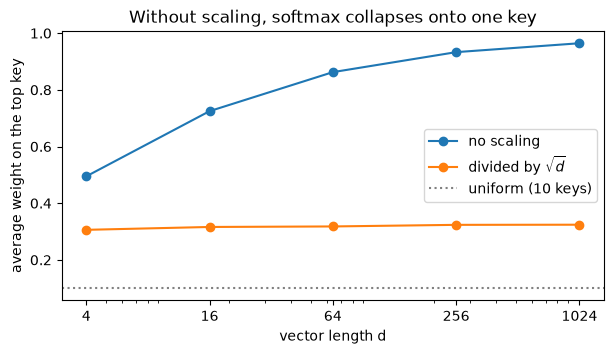

In [18]:
torch.manual_seed(0)
rows = []
for d in [4, 16, 64, 256, 1024]:
    q = torch.randn(2000, 1, d)
    k = torch.randn(2000, 10, d)
    scores = (q * k).sum(-1)                                       # 2000 queries x 10 keys
    top_raw = torch.softmax(scores, -1).max(-1).values.mean()
    top_scaled = torch.softmax(scores / math.sqrt(d), -1).max(-1).values.mean()
    rows.append((d, scores.std().item(), top_raw.item(), top_scaled.item()))
    print(f"d = {d:4d} | std of scores: {scores.std():6.1f} | top weight, no scaling: {top_raw:.2f} "
          f"| top weight, divided by sqrt(d): {top_scaled:.2f}")

ds = [r[0] for r in rows]
plt.figure(figsize=(7, 3.5))
plt.plot(ds, [r[2] for r in rows], "o-", label="no scaling")
plt.plot(ds, [r[3] for r in rows], "o-", label=r"divided by $\sqrt{d}$")
plt.axhline(0.1, color="gray", linestyle=":", label="uniform (10 keys)")
plt.xscale("log")
plt.xticks(ds, [str(d) for d in ds])
plt.xlabel("vector length d")
plt.ylabel("average weight on the top key")
plt.title("Without scaling, softmax collapses onto one key")
plt.legend()
plt.show()

The typical size of the scores doubles every time $d$ grows 4×: 2, 4, 8, 16, 32, exactly $\sqrt{d}$. Without scaling, the top key's weight climbs from 0.49 to 0.96: softmax becomes almost a hard "pick one" (the "5x sharper" query from before, taken to the extreme). That can be bad for training. When one weight is nearly 1 and the rest nearly 0, small changes to the scores barely change the output, so the gradients that would teach the model to attend elsewhere are tiny (the same reason a huge logit stalls learning in a classifier). Dividing by $\sqrt{d}$ keeps the top weight at about 0.32 no matter how long the vectors are.

Real models use $d$ of 64 or more per head (GPT-2: 64).

## Positions: Why "Dog Bites Man" Needs Them

Look at the attention function again: nothing in it knows **where** a token is. Each token is compared with every other token by content alone. So what happens if we shuffle the words?

Let's give each word an embedding, run one self-attention layer on "the dog bit the man" and on "the man bit the dog", and compare the output vector for "dog" in both sentences:

In [19]:
torch.manual_seed(0)
vocab = {"the": 0, "dog": 1, "bit": 2, "man": 3}
embed = nn.Embedding(len(vocab), d_model)


def self_attend(sentence, add_positions=False):
    ids = torch.tensor([vocab[w] for w in sentence.split()])
    X = embed(ids)
    if add_positions:
        X = X + sinusoidal_positions(len(ids), d_model)
    out, _ = attention(W_Q(X), W_K(X), W_V(X))
    return out


def sinusoidal_positions(n_positions, dim):
    # The Transformer's positional encoding: sines and cosines of different frequencies
    pos = torch.arange(n_positions)[:, None]
    freqs = torch.exp(-math.log(10000) * torch.arange(0, dim, 2) / dim)
    pe = torch.zeros(n_positions, dim)
    pe[:, 0::2] = torch.sin(pos * freqs)
    pe[:, 1::2] = torch.cos(pos * freqs)
    return pe


with torch.no_grad():
    a = self_attend("the dog bit the man")   # "dog" is word 1
    b = self_attend("the man bit the dog")   # "dog" is word 4
    print('Without positions, is "dog" the same in both sentences?', torch.allclose(a[1], b[4], atol=1e-6))

    a = self_attend("the dog bit the man", add_positions=True)
    b = self_attend("the man bit the dog", add_positions=True)
    print('With positions,    is "dog" the same in both sentences?', torch.allclose(a[1], b[4], atol=1e-6))

Without positions, is "dog" the same in both sentences? True
With positions,    is "dog" the same in both sentences? False


Without positions, "dog" gets **exactly the same vector** whether it's biting or being bitten. Self-attention only sees *which* words are in the sentence, not their order. Shuffle the words and every output is shuffled the same way, but otherwise unchanged. To self-attention alone, "the dog bit the man" and "the man bit the dog" are the same bag of words.

The fix is to add a **positional encoding** to each token's embedding before the first layer, so that "dog at position 1" and "dog at position 4" start out as different vectors. The original Transformer used sines and cosines:

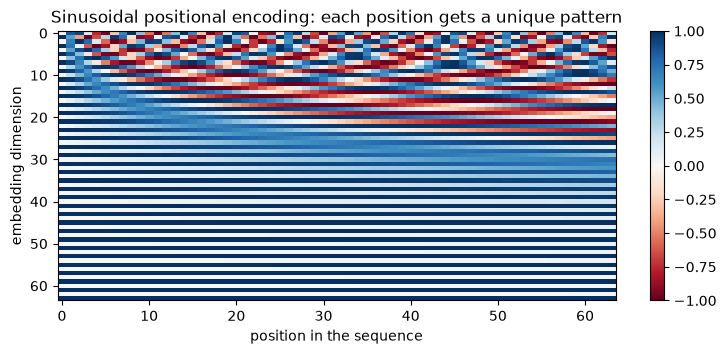

In [20]:
pe = sinusoidal_positions(64, 64)
plt.figure(figsize=(9, 3.5))
plt.imshow(pe.T, aspect="auto", cmap="RdBu")
plt.xlabel("position in the sequence")
plt.ylabel("embedding dimension")
plt.title("Sinusoidal positional encoding: each position gets a unique pattern")
plt.colorbar()
plt.show()

Each column is the vector added to the token at that position. The top rows oscillate quickly and the bottom rows slowly, like the hands of a clock. This is the same sine-and-cosine trick we used to tell the diffusion U-Net which noise step it was on (Lecture 19).

GPT-style models usually skip the formula and simply **learn** a vector for each position (`nn.Embedding(max_positions, d_model)`), which is what our tiny GPT will do.

https://blog.google/products-and-platforms/products/search/search-language-understanding-bert/

## Causal Masking: No Peeking at the Future

A GPT is trained to **predict the next token**. Given "To be, or not to b", predict "e". We train on every position of a text at once: position 1 predicts token 2, position 2 predicts token 3, and so on.

But self-attention lets every token look at every other token, *including the ones after it*. If position 1 can see token 2, predicting token 2 is trivial: just copy it. So a GPT uses a **causal mask**: each token may only attend to itself and the tokens **before** it. The mask is a lower-triangular matrix, and the blocked scores are set to $-\infty$, so softmax gives them weight 0.

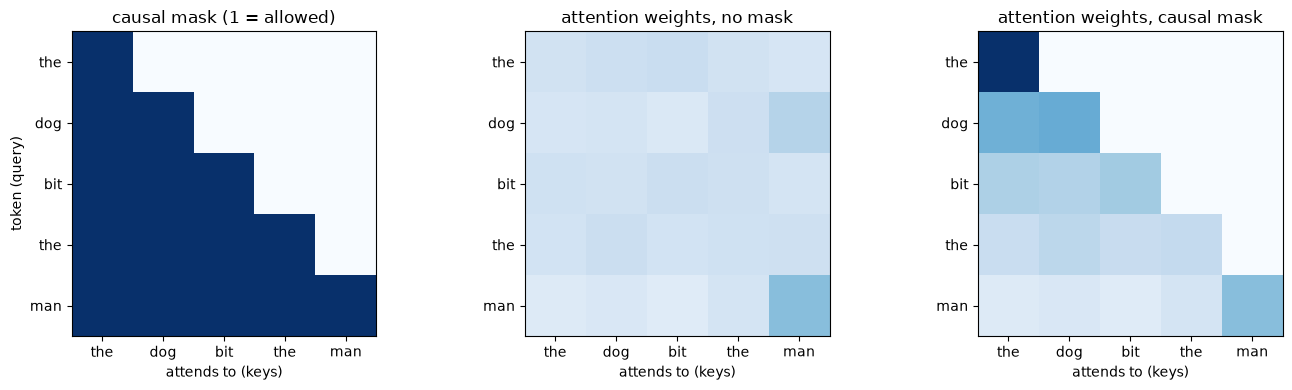

In [21]:
sentence = "the dog bit the man".split()
n = len(sentence)
mask = torch.tril(torch.ones(n, n))

with torch.no_grad():
    X = embed(torch.tensor([vocab[w] for w in sentence])) + sinusoidal_positions(n, d_model)
    _, w_full = attention(W_Q(X), W_K(X), W_V(X))
    _, w_causal = attention(W_Q(X), W_K(X), W_V(X), mask=mask)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, m, title in [(axes[0], mask, "causal mask (1 = allowed)"),
                     (axes[1], w_full, "attention weights, no mask"),
                     (axes[2], w_causal, "attention weights, causal mask")]:
    ax.imshow(m, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(n), sentence)
    ax.set_yticks(range(n), sentence)
    ax.set_xlabel("attends to (keys)")
    ax.set_title(title)
axes[0].set_ylabel("token (query)")
plt.tight_layout()
plt.show()

These weights come from untrained, random layers, so the patterns themselves don't mean anything yet. What matters is the shape: with the mask, everything above the diagonal is exactly zero. "the" (first word) can only attend to itself, and "man" can attend to the whole sentence. We'll see what happens when we forget the mask later on.

## Multi-Head Attention

One attention operation computes one set of weights per token: one idea of "what's relevant". But a word relates to its context in several ways at once. For "it" in the reading's example, one relationship is *which noun "it" refers to* and another is *what is being said about it*.

**Multi-head attention** runs several attention operations ("heads") in parallel, each with its own $W_Q$, $W_K$, $W_V$, and each working in a smaller space ($d_{\text{model}} / n_{\text{heads}}$ numbers per head). The heads' outputs are concatenated and mixed by one more linear layer. The total cost is about the same as one big head.

In code, we compute all heads' queries, keys and values with a single linear layer, then reshape so the heads become an extra batch dimension. Our `attention()` function then handles all heads at once.

In [22]:
class MultiHeadAttention(nn.Module):
    def __init__(self, d_model, n_heads, causal=True):
        super().__init__()
        assert d_model % n_heads == 0
        self.n_heads, self.d_head, self.causal = n_heads, d_model // n_heads, causal
        self.qkv = nn.Linear(d_model, 3 * d_model)   # W_Q, W_K, W_V for all heads at once
        self.proj = nn.Linear(d_model, d_model)      # mixes the heads back together
        self.last_weights = None                     # saved so we can look at them later

    def forward(self, x):
        batch, n, d_model = x.shape
        q, k, v = self.qkv(x).split(d_model, dim=-1)
        # [batch, n, d_model] -> [batch, n_heads, n, d_head]
        q, k, v = [t.view(batch, n, self.n_heads, self.d_head).transpose(1, 2) for t in (q, k, v)]
        mask = torch.tril(torch.ones(n, n, device=x.device)) if self.causal else None
        out, weights = attention(q, k, v, mask)
        self.last_weights = weights.detach()
        out = out.transpose(1, 2).reshape(batch, n, d_model)   # concatenate the heads
        return self.proj(out)


mha = MultiHeadAttention(d_model=16, n_heads=4)
x = torch.randn(2, 5, 16)                # 2 sequences, 5 tokens, 16 numbers each
print(f"input:   {tuple(x.shape)}")
print(f"output:  {tuple(mha(x).shape)}")
print(f"weights: {tuple(mha.last_weights.shape)}   (batch, heads, queries, keys)")

input:   (2, 5, 16)
output:  (2, 5, 16)
weights: (2, 4, 5, 5)   (batch, heads, queries, keys)


## Building and Training a Tiny GPT

We now have every piece. A GPT is a stack of identical **Transformer blocks**. Each block has two parts, and each part is wrapped in a residual connection with layer normalization (like batch norm, but normalizing each token's vector on its own):

1. **Multi-head self-attention**: tokens exchange information.
2. **An MLP** (two linear layers with an activation in between), applied to each token separately: each token processes what it gathered.

Before the blocks: a token embedding plus a learned position embedding. After the blocks: a linear layer that turns each token's vector into **logits** over the vocabulary, which predict the next token.

### The data: Tiny Shakespeare

About 1 MB of Shakespeare's plays. To keep things small we work with **characters** instead of words: the vocabulary is the 65 distinct characters in the text, so the model must learn spelling, words and grammar all from scratch.

In [23]:
import os, urllib.request

if not os.path.exists("input.txt"):
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt", "input.txt")
text = open("input.txt").read()

chars = sorted(set(text))
vocab_size = len(chars)
stoi = {c: i for i, c in enumerate(chars)}     # character -> integer
itos = {i: c for i, c in enumerate(chars)}     # integer -> character
encode = lambda s: [stoi[c] for c in s]
decode = lambda ids: "".join(itos[int(i)] for i in ids)

print(f"{len(text):,} characters, vocabulary of {vocab_size}")
print(repr("".join(chars)))
print(text[:250])

1,115,394 characters, vocabulary of 65
"\n !$&',-.3:;?ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyz"
First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.



In [24]:
data = torch.tensor(encode(text))
split = int(0.9 * len(data))
train_data, val_data = data[:split], data[split:]   # first 90% for training, last 10% for validation

CONTEXT = 64        # how many characters the model sees at once
BATCH_SIZE = 32


def get_batch(source):
    # Random chunks of text; the target is the same chunk shifted one character to the right
    starts = torch.randint(len(source) - CONTEXT - 1, (BATCH_SIZE,))
    x = torch.stack([source[s:s + CONTEXT] for s in starts])
    y = torch.stack([source[s + 1:s + CONTEXT + 1] for s in starts])
    return x.to(device), y.to(device)

x, y = get_batch(train_data)
print("input: ", repr(decode(x[0][:30])))
print("target:", repr(decode(y[0][:30])))

input:  'elf.\nI have advertised him by '
target: 'lf.\nI have advertised him by s'


Every position in the chunk is a training example: after "F" predict "i", after "Fi" predict "r", and so on, all 64 at once. That's why the causal mask matters.

### The model

In [25]:
class Block(nn.Module):
    def __init__(self, d_model, n_heads, causal=True):
        super().__init__()
        self.ln1 = nn.LayerNorm(d_model)
        self.attn = MultiHeadAttention(d_model, n_heads, causal)
        self.ln2 = nn.LayerNorm(d_model)
        self.mlp = nn.Sequential(nn.Linear(d_model, 4 * d_model), nn.GELU(), nn.Linear(4 * d_model, d_model))

    def forward(self, x):
        x = x + self.attn(self.ln1(x))   # tokens exchange information (+ residual)
        x = x + self.mlp(self.ln2(x))    # each token processes it (+ residual)
        return x


class TinyGPT(nn.Module):
    def __init__(self, vocab_size, d_model=96, n_heads=4, n_layers=3, context=CONTEXT, causal=True):
        super().__init__()
        self.context = context
        self.token_emb = nn.Embedding(vocab_size, d_model)
        self.pos_emb = nn.Embedding(context, d_model)        # a learned vector for each position
        self.blocks = nn.ModuleList([Block(d_model, n_heads, causal) for _ in range(n_layers)])
        self.ln = nn.LayerNorm(d_model)
        self.head = nn.Linear(d_model, vocab_size)           # vector -> logits over characters

    def forward(self, idx):
        positions = torch.arange(idx.shape[1], device=idx.device)
        x = self.token_emb(idx) + self.pos_emb(positions)
        for block in self.blocks:
            x = block(x)
        return self.head(self.ln(x))                         # [batch, n, vocab_size]


@torch.no_grad()
def generate(model, prompt, n_chars=300, temperature=1.0, top_k=None, seed=0):
    model.eval()
    gen = torch.Generator(device="cpu").manual_seed(seed)
    idx = torch.tensor([encode(prompt)], device=device)
    for _ in range(n_chars):
        logits = model(idx[:, -model.context:])[0, -1] / temperature   # logits for the next character
        if top_k is not None:
            cutoff = torch.topk(logits, top_k).values[-1]
            logits[logits < cutoff] = float("-inf")                    # keep only the top k
        probs = torch.softmax(logits, dim=-1).cpu()
        next_id = torch.multinomial(probs, 1, generator=gen)
        idx = torch.cat([idx, next_id.view(1, 1).to(device)], dim=1)
    return decode(idx[0])


torch.manual_seed(42)
gpt = TinyGPT(vocab_size).to(device)
print(f"Parameters: {sum(p.numel() for p in gpt.parameters()):,}")
print("\nBefore training:\n" + generate(gpt, "ROMEO:\n", n_chars=200))

Parameters: 354,401

Before training:
ROMEO:
t3yxlmhmkdvARxLsXltUWRjHKu
?eaaj!U&aNdfIxAlsvSBUMyFcRu$By$Xzfnt;zkVrM z&?j DoRbsOEHelC!BTg3xUhPRCslUa-s3KypoWWiXWMv
JIRc:sZu;yJUfHer?nK-emj$fxzsBAxMLVyPjJRDfWBi'fxIiVezEttB,DkJDscLb'
szuzzW3u!SBC.SVva


Random weights give random characters. Now let's train it: the loss is **cross-entropy** on the next character, exactly the loss we used for classification since Lecture 13, applied at every position.

A useful reference point: guessing uniformly among 65 characters gives a loss of $\ln 65 \approx 4.17$.

In [26]:
@torch.no_grad()
def estimate_loss(model, source, n_batches=20):
    model.eval()
    losses = []
    for _ in range(n_batches):
        x, y = get_batch(source)
        losses.append(F.cross_entropy(model(x).view(-1, vocab_size), y.view(-1)).item())
    model.train()
    return np.mean(losses)


def train_gpt(model, steps, lr=3e-3, eval_every=500):
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr)
    history = {"step": [], "train": [], "val": []}
    start = time.time()
    model.train()
    for step in range(1, steps + 1):
        x, y = get_batch(train_data)
        loss = F.cross_entropy(model(x).view(-1, vocab_size), y.view(-1))
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        if step % eval_every == 0 or step == steps:
            history["step"].append(step)
            history["train"].append(estimate_loss(model, train_data))
            history["val"].append(estimate_loss(model, val_data))
            print(f"Step {step:5d} | train loss {history['train'][-1]:.3f} | val loss {history['val'][-1]:.3f} "
                  f"| {time.time() - start:.0f} s")
    return history


history = train_gpt(gpt, steps=3000)

Step   500 | train loss 1.839 | val loss 1.979 | 5 s
Step  1000 | train loss 1.615 | val loss 1.798 | 11 s
Step  1500 | train loss 1.543 | val loss 1.727 | 17 s
Step  2000 | train loss 1.482 | val loss 1.700 | 22 s
Step  2500 | train loss 1.438 | val loss 1.647 | 27 s
Step  3000 | train loss 1.455 | val loss 1.622 | 33 s


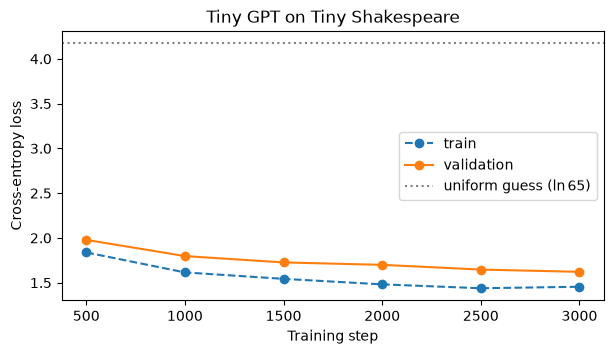

After training:
ROMEO:
Thy farms kind sell medect ueament, in I the earth
of thy hount beare his death being some one cost.

BUSHY:
Will yet he should forfeit; my father well stand.

Shepiness,
By chesconclusting up near: and to faith.

First Woes, Has
Noting of lively my infect'd to the nest.
So, Spy Lord England Citizens?
.
How down, the loving of it.
Do now sometime and of heavens made full of well will them?

LADY CAPULET:
Best I am was I am cout, and time to entreat;
Forgethful one oother to lock-blood Apholet,
B


In [27]:
plt.figure(figsize=(7, 3.5))
plt.plot(history["step"], history["train"], "o--", label="train")
plt.plot(history["step"], history["val"], "o-", label="validation")
plt.axhline(math.log(vocab_size), color="gray", linestyle=":", label=r"uniform guess ($\ln 65$)")
plt.xlabel("Training step")
plt.ylabel("Cross-entropy loss")
plt.title("Tiny GPT on Tiny Shakespeare")
plt.legend()
plt.show()

print("After training:\n" + generate(gpt, "ROMEO:\n", n_chars=500))

The validation loss falls from 2.0 (guessing) to about **1.5** in 3,000 steps, about 30 minutes on a CPU. Train and validation stay close, so with 354,000 parameters and a million characters, the model isn't memorizing the text.

And the output is recognizably Shakespeare-shaped. In order of difficulty, the model learned:

- **Format**: a speaker's name in capitals followed by a colon, a line break, lines of verse, a blank line between speeches. It even uses real character names from the plays, such as BUSHY and LADY CAPULET.
- **Words**: mostly real English words ("the earth", "his death", "heavens", "entreat"), with some invented ones ("medect", "neightingbroke").
- **Grammar, a little**: short phrases work ("to entreat", "the loving of it"), but sentences don't mean anything.

All of this came from predicting one character at a time, with 64 characters of context. Nobody told it what a word or a speaker is.

## Sampling: Temperature and Top-k

At each step the model outputs logits for all 65 characters, and `generate()` **samples** the next character from the softmax probabilities. Two knobs change how:

- **Temperature**: divide the logits by $T$ before softmax. $T < 1$ sharpens the distribution (more predictable text), $T > 1$ flattens it (more surprising text). Remember the soft lookup at the start: multiplying the query by 5 sharpened the weights in the same way.
- **Top-k**: keep only the $k$ most likely characters, and sample among those.

Here's the model's prediction for the character after "To be, or not to b":

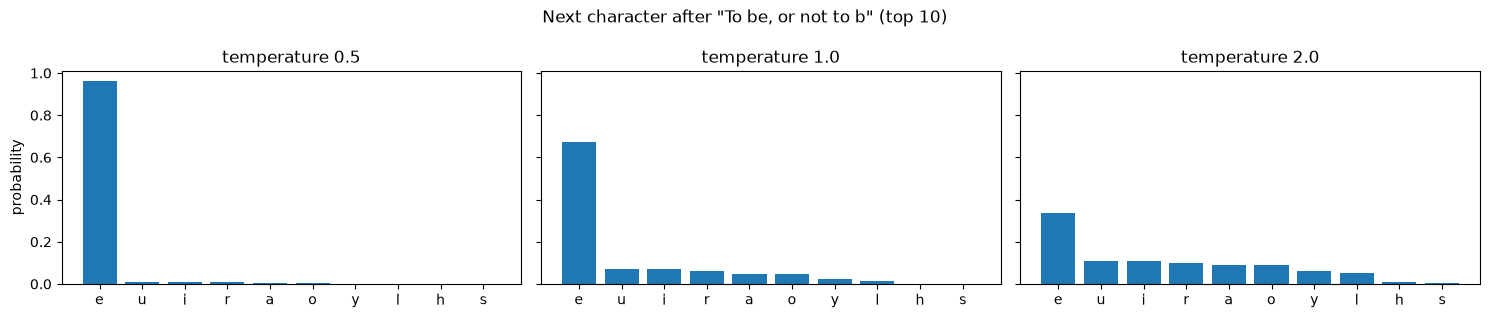

In [29]:
prompt = "To be, or not to b"
with torch.no_grad():
    gpt.eval()
    logits = gpt(torch.tensor([encode(prompt)], device=device))[0, -1].cpu()

fig, axes = plt.subplots(1, 3, figsize=(15, 3.2), sharey=True)
for ax, T in zip(axes, [0.5, 1.0, 2.0]):
    probs = torch.softmax(logits / T, dim=-1)
    top = torch.topk(probs, 10)
    ax.bar([repr(itos[int(i)])[1:-1] for i in top.indices], top.values)
    ax.set_title(f"temperature {T}")
axes[0].set_ylabel("probability")
fig.suptitle(f'Next character after "{prompt}" (top 10)')
plt.tight_layout()
plt.show()

In [30]:
for T, k in [(0.5, None), (1.0, None), (1.5, None), (1.5, 5)]:
    label = f"temperature {T}" + (f", top-k {k}" if k else "")
    print(f"===== {label} =====")
    print(generate(gpt, "ROMEO:\n", n_chars=250, temperature=T, top_k=k, seed=1))
    print()

===== temperature 0.5 =====
ROMEO:
What speak not but all the perform of the son,
To carried the field the witstmust and gagest here?
That thou she doth thy counsel
With the state of that your head many manth is the earth
And the true noble properides and that we shall have them to be

===== temperature 1.0 =====
ROMEO:
What; the repeneruence's patience a kind.

BUSHY:
Thy device colver, infil. O, Wail, now, stay
Which gradge puty, brothert to Romans:
his then reved by this put admingman burn'd
And while them, I precincely hath advisabour at we
some that power told 

===== temperature 1.5 =====
ROMEO:
But, suquers! murustly'd.
Itjry, you come, or name virtuear, callemn
Henribox, aroal!
Washe, we's notgratoof foe! Made
Bytterniby, sirrahoster revock,, Tybark, Aude,
Camy burized to him revoft, it rebn'd livel,
Indewing dendter is,
Fooh hipbeasses,
S

===== temperature 1.5, top-k 5 =====
ROMEO:
What speak not but in a chaise, by my shame winto me,
As a thy weep, trail shall be to more.

S

The bar charts show what temperature does to one prediction. The model is fairly sure "e" comes next (67% at temperature 1). At 0.5 that becomes a near-certainty (96%), and at 2.0 the other letters catch up and "e" drops to 34%.

In the generated text:

- **Temperature 0.5**: the safest, most "average" text: common words, smooth lines ("What speak not but all the perform of the son"). Lower still, models tend to get repetitive.
- **Temperature 1.0**: samples straight from what the model learned: more varied, a few invented words.
- **Temperature 1.5**: unlikely characters get chosen often enough to break words apart ("murustly'd", "Henribox, aroal!").
- **Temperature 1.5 with top-k 5**: the same high temperature, but only the 5 most likely characters are allowed, which removes the worst choices. The text is varied but stays readable.

Chatbots use the same knobs: low temperature for factual answers, higher for brainstorming, with top-k or a similar cutoff to avoid nonsense.

### What are the heads looking at?

Our `MultiHeadAttention` saved its weights on the last forward pass. Let's feed in a line of text and look at what each head in the first and last layer attends to.

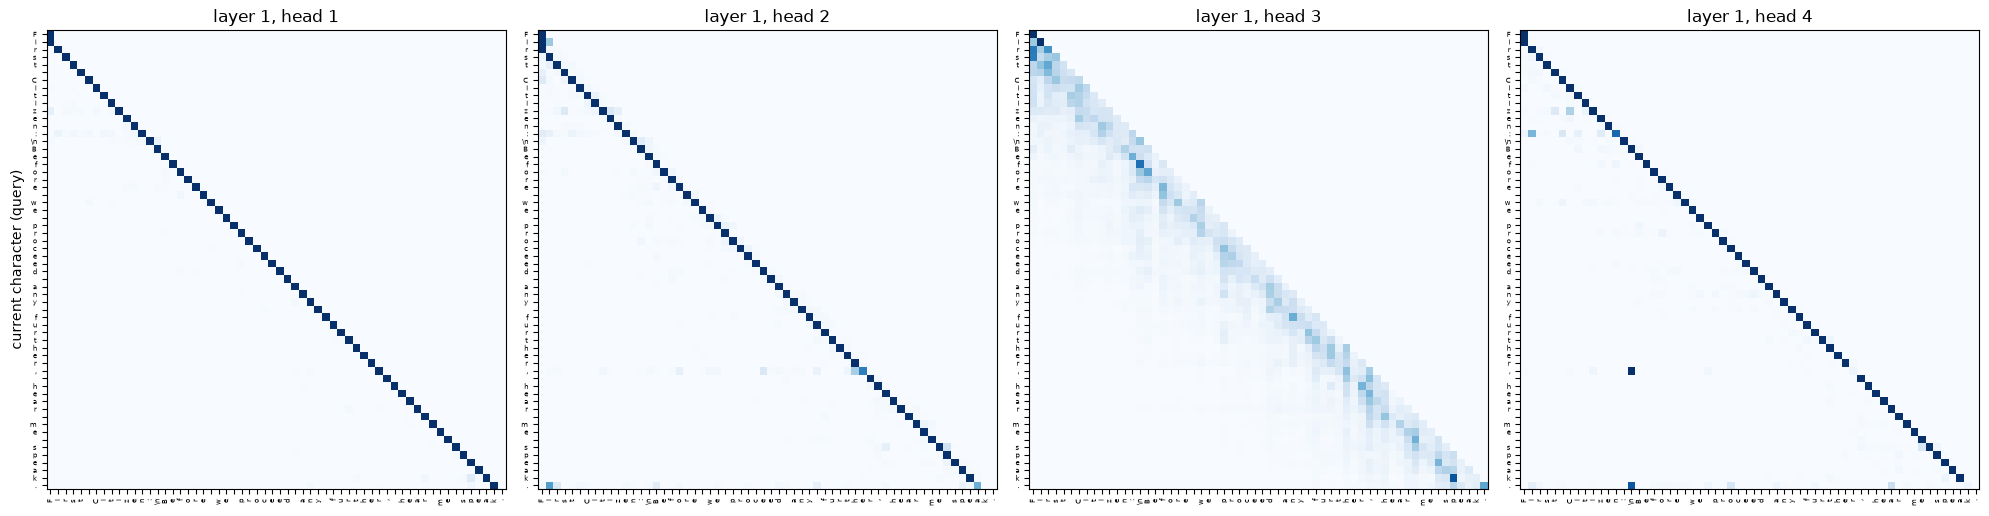

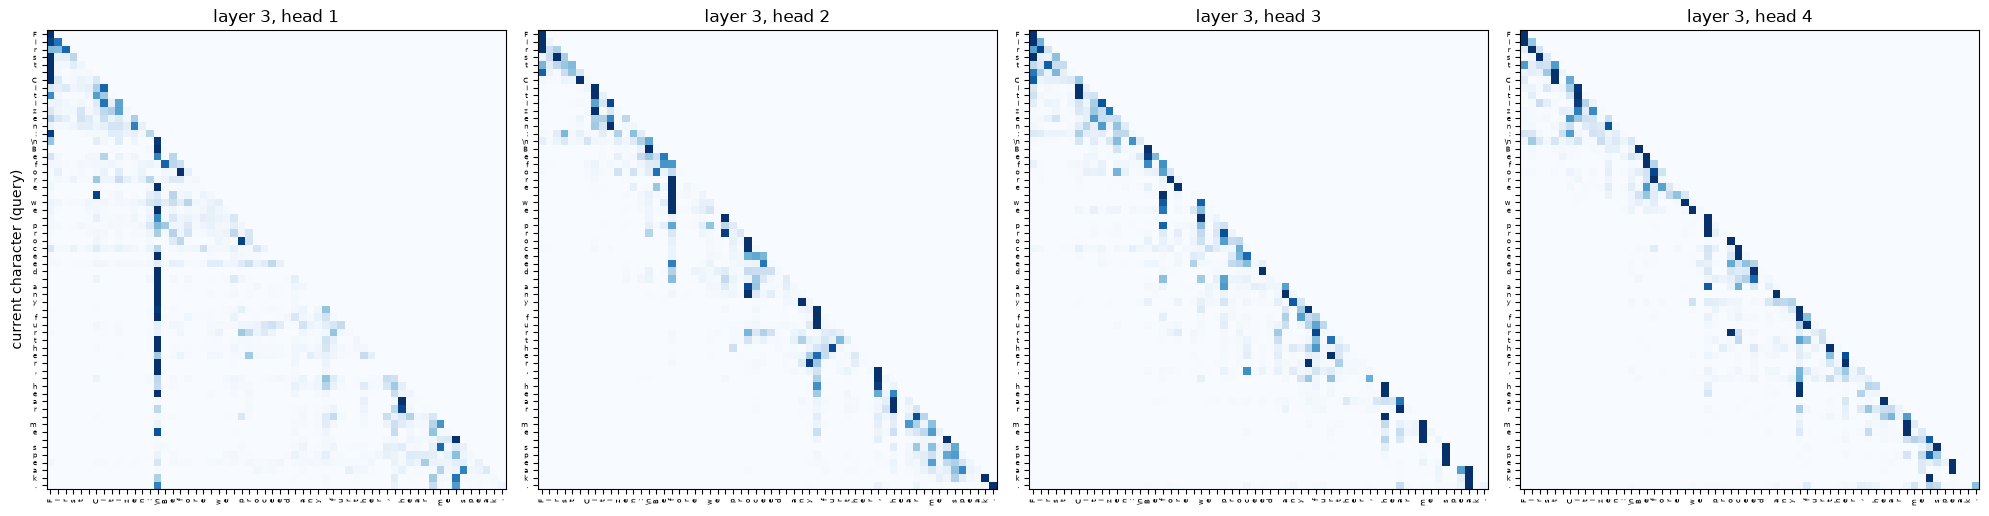

In [31]:
snippet = "First Citizen:\nBefore we proceed any further, hear me speak."
labels = [repr(c)[1:-1] for c in snippet]
with torch.no_grad():
    gpt.eval()
    gpt(torch.tensor([encode(snippet)], device=device))

for layer in [0, len(gpt.blocks) - 1]:
    weights = gpt.blocks[layer].attn.last_weights[0].cpu()   # [heads, n, n]
    fig, axes = plt.subplots(1, weights.shape[0], figsize=(20, 5.2))
    for h, ax in enumerate(axes):
        ax.imshow(weights[h], cmap="Blues", vmin=0, vmax=0.6)
        ax.set_title(f"layer {layer + 1}, head {h + 1}")
        ax.set_xticks(range(len(snippet)), labels, fontsize=5, rotation=90)
        ax.set_yticks(range(len(snippet)), labels, fontsize=5)
    axes[0].set_ylabel("current character (query)")
    plt.tight_layout()
    plt.show()

Each row is one character, and its darkest squares show which earlier characters it pays attention to. (Everything above the diagonal is empty: the causal mask.)

- **Layer 1**: three heads mostly attend to the **current character itself** (the dark diagonal), so they're passing along "what letter am I?" Head 3 spreads its attention over the **last few characters**: a "what did I just read?" head.
- **Layer 3**: the patterns are more structured. Head 1 has a dark vertical stripe at the **line break**: for most of the second line, characters look back at where the line started. Heads 2-4 form **staircases**, where the characters of a word look back to the start of their word or the space before it.

Nobody programmed these roles. Different heads specialized because that helped predict the next character: knowing where you are within the current word, and within the current line, both matter for spelling and verse. This is the multi-head idea in action.

## Inside GPT-2

GPT-2 (OpenAI, 2019) is the model from Lecture 15. Architecturally it's **our tiny GPT, scaled up**: the same blocks, the same causal mask, the same learned position embeddings, the same next-token loss. The differences are size, and that it works on **subword tokens** instead of characters (the tokenizer from Lecture 15). We ask Hugging Face for the attention weights (`attn_implementation="eager"` makes the model compute them explicitly so it can return them).

In [32]:
from transformers import AutoTokenizer, AutoModelForCausalLM

tokenizer = AutoTokenizer.from_pretrained("openai-community/gpt2")
gpt2 = AutoModelForCausalLM.from_pretrained("openai-community/gpt2", attn_implementation="eager").to(device).eval()

cfg = gpt2.config
print(f"GPT-2:     {sum(p.numel() for p in gpt2.parameters()):>12,} parameters | {cfg.n_layer} layers, "
      f"{cfg.n_head} heads, {cfg.n_embd} dims, context {cfg.n_positions} tokens, vocabulary {cfg.vocab_size:,}")
print(f"Tiny GPT:  {sum(p.numel() for p in gpt.parameters()):>12,} parameters | {len(gpt.blocks)} layers, "
      f"4 heads, 96 dims, context {CONTEXT} characters, vocabulary {vocab_size}")

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

GPT-2:      124,439,808 parameters | 12 layers, 12 heads, 768 dims, context 1024 tokens, vocabulary 50,257
Tiny GPT:       354,401 parameters | 3 layers, 4 heads, 96 dims, context 64 characters, vocabulary 65


### Which word does "it" look at?

The reading's example: in "The animal didn't cross the street because it was too tired", "it" refers to the animal. GPT-2 has 12 layers × 12 heads = 144 attention heads. For each one, let's measure how much attention "it" pays to "animal" vs. "street".

['The', 'Ġanimal', 'Ġdidn', "'t", 'Ġcross', 'Ġthe', 'Ġstreet', 'Ġbecause', 'Ġit', 'Ġwas', 'Ġtoo', 'Ġtired']


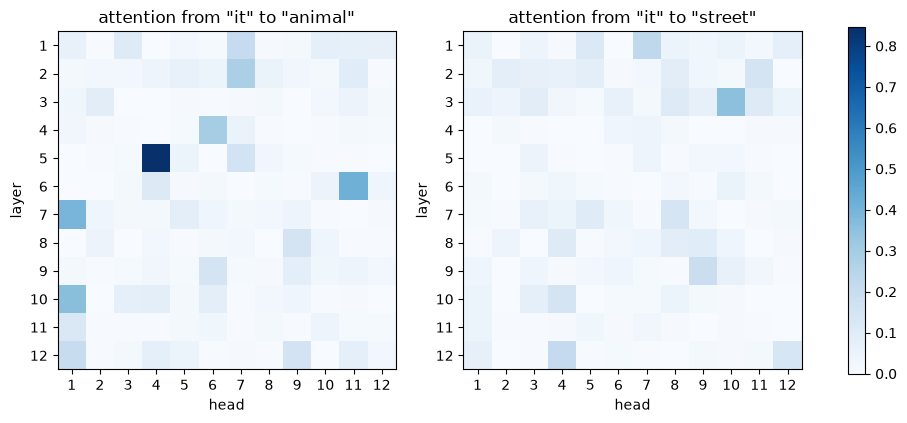

Head with the most attention from "it" to "animal": layer 5, head 4 (0.85 on "animal", 0.00 on "street")


In [33]:
sentence = "The animal didn't cross the street because it was too tired"
inputs = tokenizer(sentence, return_tensors="pt").to(device)
tokens = tokenizer.convert_ids_to_tokens(inputs.input_ids[0])
print(tokens)   # "Ġ" marks a space before the word

with torch.inference_mode():
    out = gpt2(**inputs, output_attentions=True)
att = torch.stack(out.attentions)[:, 0].cpu()   # [layers, heads, tokens, tokens]

find = lambda word: next(i for i, t in enumerate(tokens) if t.replace("Ġ", "") == word)
i_it, i_animal, i_street = find("it"), find("animal"), find("street")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, j, word in [(axes[0], i_animal, "animal"), (axes[1], i_street, "street")]:
    im = ax.imshow(att[:, :, i_it, j], cmap="Blues", vmin=0, vmax=att[:, :, i_it, [i_animal, i_street]].max())
    ax.set_title(f'attention from "it" to "{word}"')
    ax.set_xlabel("head")
    ax.set_ylabel("layer")
    ax.set_xticks(range(12), range(1, 13))
    ax.set_yticks(range(12), range(1, 13))
fig.colorbar(im, ax=axes)
plt.show()

layer, head = divmod(int(att[:, :, i_it, i_animal].argmax()), 12)
print(f'Head with the most attention from "it" to "animal": layer {layer + 1}, head {head + 1} '
      f'({att[layer, head, i_it, i_animal]:.2f} on "animal", {att[layer, head, i_it, i_street]:.2f} on "street")')

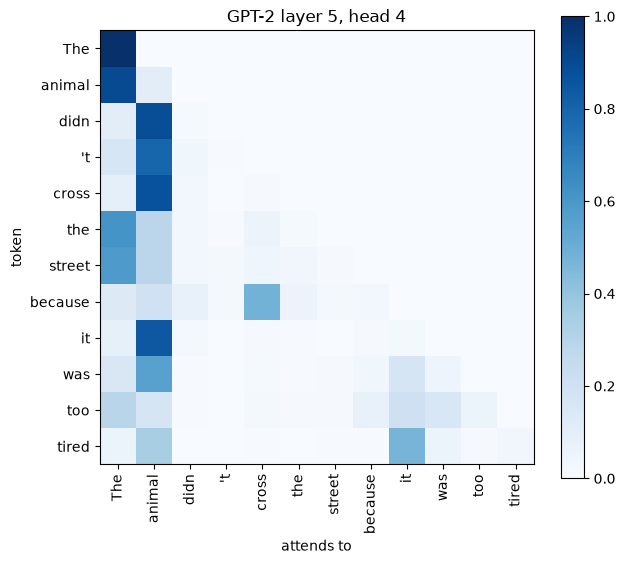

In [34]:
clean = [t.replace("Ġ", "") for t in tokens]
plt.figure(figsize=(7, 6))
plt.imshow(att[layer, head], cmap="Blues")
plt.xticks(range(len(clean)), clean, rotation=90)
plt.yticks(range(len(clean)), clean)
plt.xlabel("attends to")
plt.ylabel("token")
plt.title(f"GPT-2 layer {layer + 1}, head {head + 1}")
plt.colorbar()
plt.show()

Look at the two heatmaps: most of the 144 heads pay little attention from "it" to either noun. A few heads, typically in the middle and later layers, put clearly more weight on "animal" than on "street". These are the heads that track what a pronoun refers to.

One important difference from the reading: GPT-2 is **causal**. When it processes "it", it hasn't seen "was too tired" yet, so "it" can't use the end of the sentence to decide. The reading's example comes from an encoder that sees the whole sentence at once (like CLIP's text encoder, or BERT). Try ending the sentence with "wide" instead of "tired": the attention from "it" can't change, because everything before "it" is identical.

### Generating with GPT-2

The same temperature and top-k knobs, now on a real language model:

In [35]:
prompt = "Data science is"
inputs = tokenizer(prompt, return_tensors="pt").to(device)
for T in [0.3, 0.8, 1.5]:
    torch.manual_seed(0)
    ids = gpt2.generate(**inputs, max_new_tokens=40, do_sample=True, temperature=T, top_k=50,
                        pad_token_id=tokenizer.eos_token_id)
    print(f"===== temperature {T} =====")
    print(tokenizer.decode(ids[0]))
    print()

===== temperature 0.3 =====
Data science is a fundamental part of our lives and is the cornerstone of our understanding of the world around us. We are constantly learning about the world around us and how it impacts our lives.

We are constantly

===== temperature 0.8 =====
Data science is a fundamental part of our lives and is crucial to human survival. Our knowledge of how the Earth works and processes is essential to the lives of all living things.

Earth science helps our understanding of

===== temperature 1.5 =====
Data science is a fundamental part of our lives...<|endoftext|>



The same pattern as our tiny GPT, now with words. Low temperature gives safe, generic sentences, sometimes repeating themselves. Around 0.8 the text is varied but coherent. At 1.5 it drifts off topic and loses grammar, even with top-k. GPT-2 is a 2019 model with 124 million parameters, so even its best output wanders after a sentence or two. Today's chatbots are the same kind of model, much larger and trained on far more text.